# Lab 04 — ANN Patch Classification (Urban vs Forest)

Task 1: classify **200×200 Sentinel-2 RGB patches** as forest or urban with a simple dense ANN (TensorFlow / Keras), in the spirit of the diode introductory notebook.

| File | Class |
|---|---|
| `s2_forest.png` | Forest (label 0) |
| `s2_urban.png` | Urban (label 1) |

We build a spatial train/test split, define a barebone ANN, run **≥5 architecture / optimiser permutations**, and compare the approach with the Bayesian classifier from Lab 3.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

%matplotlib inline
np.random.seed(0)
tf.random.set_seed(0)

print('TensorFlow', tf.__version__)

TensorFlow 2.19.0


## 1. Posing the task as a function

An ANN can approximate a mapping if we write the problem as a function.

Let a patch be a tensor $X \in [0,1]^{200 \times 200 \times 3}$ (normalised RGB).
The unknown labelling function is

$$
f: X \mapsto y, \qquad y \in \{0,1\}
$$

with $y=0$ for forest and $y=1$ for urban. Training examples are pairs $(X_i, y_i)$ cut from labelled large scenes. The network learns parameters $\theta$ of a parametric surrogate $\hat{f}_\theta \approx f$, typically outputting $p(y=1\mid X)$ via a sigmoid. Once that function form is clear, supervised learning (here: a dense ANN) applies.

## 2. Create training / test data (200×200 patches)

**Spatial split** (avoids leakage from overlapping neighbours):
- **Train:** left 70% of each large image, stride 100 px
- **Test:** right 30%, stride 200 px (non-overlapping-ish hold-out)

In [2]:
PATCH = 200


def load_rgb(path):
    return np.array(Image.open(path).convert('RGB'))


def extract_patches(img, x0, x1, size=PATCH, stride=100):
    """Cut RGB patches with top-left x in [x0, x1)."""
    h, w = img.shape[:2]
    patches = []
    for y in range(0, h - size + 1, stride):
        for x in range(x0, x1 - size + 1, stride):
            patches.append(img[y:y + size, x:x + size])
    return np.asarray(patches, dtype=np.float32) / 255.0


forest = load_rgb('s2_forest.png')
urban = load_rgb('s2_urban.png')
print('forest', forest.shape, '| urban', urban.shape)

split = int(0.7 * forest.shape[1])
print('Spatial split at column', split)

Xf_tr = extract_patches(forest, 0, split, stride=100)
Xu_tr = extract_patches(urban, 0, split, stride=100)
Xf_te = extract_patches(forest, split, forest.shape[1], stride=200)
Xu_te = extract_patches(urban, split, urban.shape[1], stride=200)

X_train = np.concatenate([Xf_tr, Xu_tr], axis=0)
y_train = np.array([0] * len(Xf_tr) + [1] * len(Xu_tr), dtype=np.float32)
X_test = np.concatenate([Xf_te, Xu_te], axis=0)
y_test = np.array([0] * len(Xf_te) + [1] * len(Xu_te), dtype=np.float32)

idx = np.random.permutation(len(X_train))
X_train, y_train = X_train[idx], y_train[idx]

print(f'Train patches: {len(X_train)}  (forest {len(Xf_tr)}, urban {len(Xu_tr)})')
print(f'Test  patches: {len(X_test)}  (forest {len(Xf_te)}, urban {len(Xu_te)})')

forest (1080, 1470, 3) | urban (1080, 1470, 3)
Spatial split at column 1029
Train patches: 162  (forest 81, urban 81)
Test  patches: 20  (forest 10, urban 10)


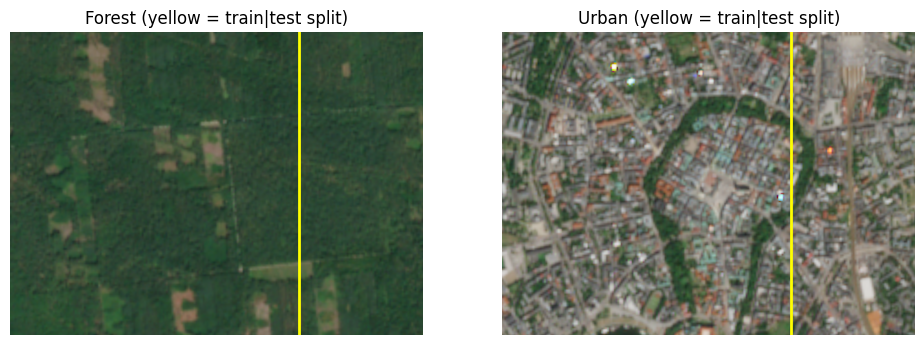

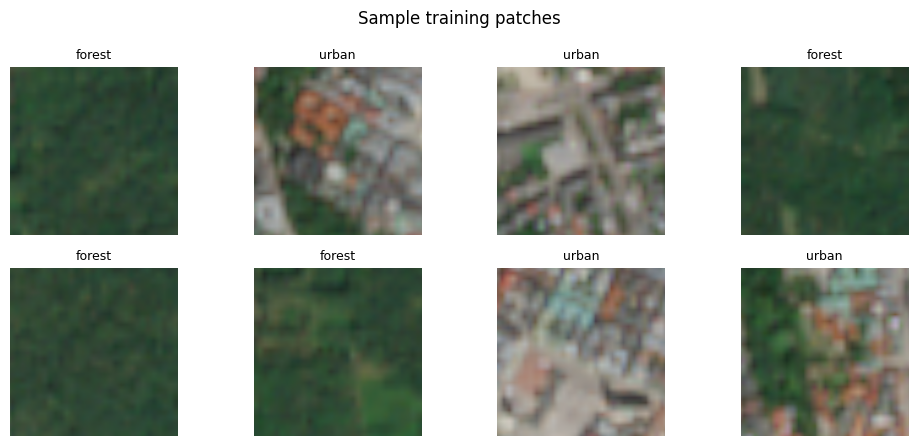

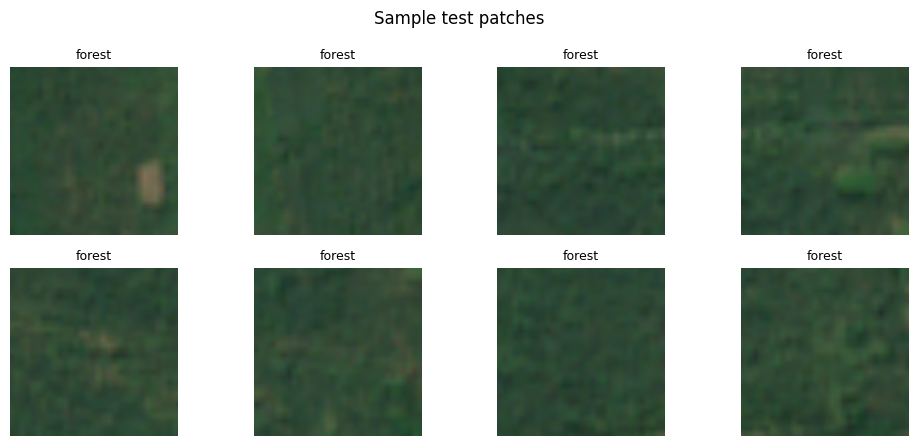

In [3]:
def show_patch_grid(X, y, title, n=8):
    fig, axes = plt.subplots(2, n // 2, figsize=(10, 4.5))
    for ax, img, lab in zip(axes.ravel(), X[:n], y[:n]):
        ax.imshow(img)
        ax.set_title('urban' if lab == 1 else 'forest', fontsize=9)
        ax.axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].imshow(forest); axes[0].axvline(split, color='yellow', linewidth=2)
axes[0].set_title('Forest (yellow = train|test split)'); axes[0].axis('off')
axes[1].imshow(urban); axes[1].axvline(split, color='yellow', linewidth=2)
axes[1].set_title('Urban (yellow = train|test split)'); axes[1].axis('off')
plt.tight_layout(); plt.show()

show_patch_grid(X_train, y_train, 'Sample training patches')
show_patch_grid(X_test, y_test, 'Sample test patches')

## 3. Barebone ANN architecture

*(Lab wording “baritone” → **barebone**.)*

Minimal supervised classifier for a patch:

1. **Flatten** $200\times200\times3 \rightarrow 120\,000$ features
2. One small **Dense** hidden layer (ReLU)
3. **Dense(1, sigmoid)** → $P(y=\text{urban}\mid X)$

Loss: binary cross-entropy. This already has **~1.9M parameters** for a 16-unit hidden layer — far more than Lab 3’s Gaussian means/covariances.

In [4]:
def build_ann(hidden_units=(16,), activations=('relu',), dropout=0.0):
    """Barebone / configurable Dense ANN for 200x200x3 patches."""
    layers = [tf.keras.layers.Input(shape=(PATCH, PATCH, 3)),
              tf.keras.layers.Flatten()]
    for units, act in zip(hidden_units, activations):
        layers.append(tf.keras.layers.Dense(units, activation=act))
        if dropout > 0:
            layers.append(tf.keras.layers.Dropout(dropout))
    layers.append(tf.keras.layers.Dense(1, activation='sigmoid'))
    return tf.keras.Sequential(layers)


baseline = build_ann(hidden_units=(16,), activations=('relu',))
baseline.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 120000)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │     1,920,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,920,033 (7.32 MB)

 Trainable params: 1,920,033 (7.32 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Experiments — five permutations

Each run uses the same data, 40 epochs, batch size 16. We log train/test accuracy & loss and wall-clock time.

In [5]:
EPOCHS = 40
BATCH = 16


def run_experiment(name, make_model, optimizer):
    """Train one ANN permutation. make_model is a zero-arg factory."""
    np.random.seed(0)
    tf.random.set_seed(0)
    model = make_model()
    model.compile(optimizer=optimizer,
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    t0 = time.time()
    history = model.fit(
        X_train, y_train,
        epochs=EPOCHS,
        batch_size=BATCH,
        validation_data=(X_test, y_test),
        verbose=0,
    )
    elapsed = time.time() - t0
    train_loss, train_acc = model.evaluate(X_train, y_train, verbose=0)
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    print(f'{name:28s}  params={model.count_params():7d}  '
          f'train_acc={train_acc:.3f}  test_acc={test_acc:.3f}  '
          f'time={elapsed:.1f}s')
    return {
        'name': name,
        'params': int(model.count_params()),
        'train_acc': float(train_acc),
        'test_acc': float(test_acc),
        'train_loss': float(train_loss),
        'test_loss': float(test_loss),
        'time_s': elapsed,
        'history': history.history,
        'model': model,
    }


experiments = []

experiments.append(run_experiment(
    '1 Baseline (16 ReLU, Adam)',
    lambda: build_ann((16,), ('relu',)),
    tf.keras.optimizers.Adam(1e-3),
))

experiments.append(run_experiment(
    '2 Wider (64 ReLU, Adam)',
    lambda: build_ann((64,), ('relu',)),
    tf.keras.optimizers.Adam(1e-3),
))

experiments.append(run_experiment(
    '3 Deeper+Dropout (64-32)',
    lambda: build_ann((64, 32), ('relu', 'relu'), dropout=0.2),
    tf.keras.optimizers.Adam(1e-3),
))

experiments.append(run_experiment(
    '4 Tanh hidden (32, Adam)',
    lambda: build_ann((32,), ('tanh',)),
    tf.keras.optimizers.Adam(1e-3),
))

experiments.append(run_experiment(
    '5 SGD+momentum (32 ReLU)',
    lambda: build_ann((32,), ('relu',)),
    tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
))


1 Baseline (16 ReLU, Adam)    params=1920033  train_acc=1.000  test_acc=1.000  time=4.3s


2 Wider (64 ReLU, Adam)       params=7680129  train_acc=1.000  test_acc=1.000  time=10.1s


3 Deeper+Dropout (64-32)      params=7682177  train_acc=1.000  test_acc=1.000  time=10.6s


4 Tanh hidden (32, Adam)      params=3840065  train_acc=0.500  test_acc=0.500  time=6.1s


5 SGD+momentum (32 ReLU)      params=3840065  train_acc=0.500  test_acc=0.500  time=4.2s


## 5. Consolidated findings

In [6]:
results = pd.DataFrame([
    {k: v for k, v in e.items() if k not in ('history', 'model')}
    for e in experiments
]).set_index('name')

display(results.round(3))

best = max(experiments, key=lambda e: e['test_acc'])
print('Best by test accuracy:', best['name'],
      f"(test_acc={best['test_acc']:.3f}, params={best['params']})")

,params,train_acc,test_acc,train_loss,test_loss,time_s
name,,,,,,
"1 Baseline (16 ReLU, Adam)",1920033,1.0,1.0,0.001,0.000,4.282
"2 Wider (64 ReLU, Adam)",7680129,1.0,1.0,0.001,0.000,10.057
3 Deeper+Dropout (64-32),7682177,1.0,1.0,0.004,0.001,10.609
"4 Tanh hidden (32, Adam)",3840065,0.5,0.5,0.693,0.693,6.062
5 SGD+momentum (32 ReLU),3840065,0.5,0.5,0.693,0.693,4.173


Best by test accuracy: 1 Baseline (16 ReLU, Adam) (test_acc=1.000, params=1920033)


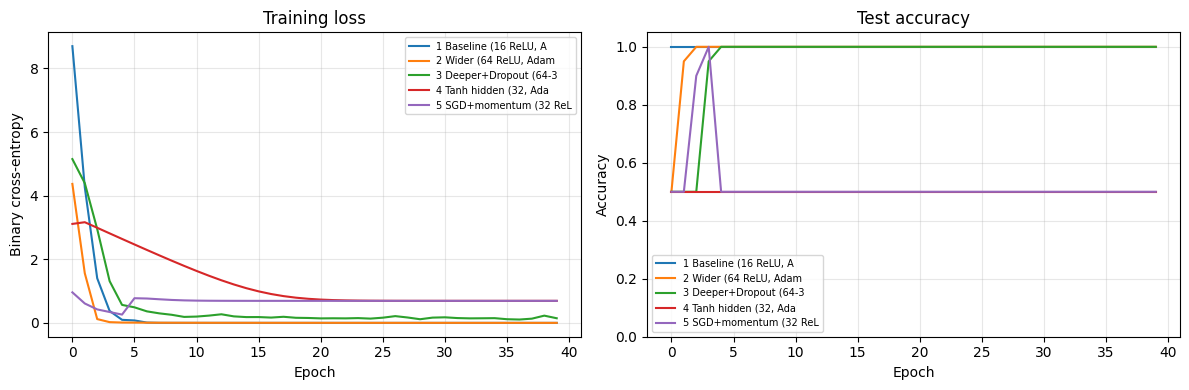

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for e in experiments:
    axes[0].plot(e['history']['loss'], label=e['name'][:22])
    axes[1].plot(e['history']['val_accuracy'], label=e['name'][:22])

axes[0].set_title('Training loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Binary cross-entropy')
axes[0].grid(True, alpha=0.3); axes[0].legend(fontsize=7)

axes[1].set_title('Test accuracy')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0, 1.05)
axes[1].grid(True, alpha=0.3); axes[1].legend(fontsize=7)

plt.tight_layout()
plt.show()

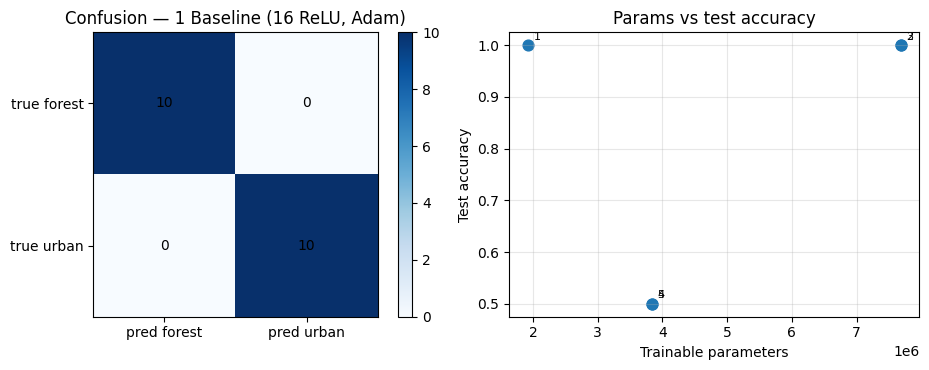

Confusion matrix [rows=true, cols=pred]:
 [[10  0]
 [ 0 10]]


In [8]:
# Confusion matrix + sample predictions for the best model
y_prob = best['model'].predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)
y_true = y_test.astype(int)

cm = np.zeros((2, 2), dtype=int)
for t, p in zip(y_true, y_pred):
    cm[t, p] += 1

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
im = axes[0].imshow(cm, cmap='Blues')
axes[0].set_xticks([0, 1]); axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(['pred forest', 'pred urban'])
axes[0].set_yticklabels(['true forest', 'true urban'])
axes[0].set_title(f"Confusion — {best['name']}")
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, str(cm[i, j]), ha='center', va='center', color='black')
fig.colorbar(im, ax=axes[0], fraction=0.046)

# parameter count vs test accuracy
axes[1].scatter(results['params'], results['test_acc'], s=60)
for name, row in results.iterrows():
    axes[1].annotate(name.split(' ', 1)[0], (row['params'], row['test_acc']),
                     textcoords='offset points', xytext=(4, 4), fontsize=8)
axes[1].set_xlabel('Trainable parameters')
axes[1].set_ylabel('Test accuracy')
axes[1].set_title('Params vs test accuracy')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('Confusion matrix [rows=true, cols=pred]:\n', cm)

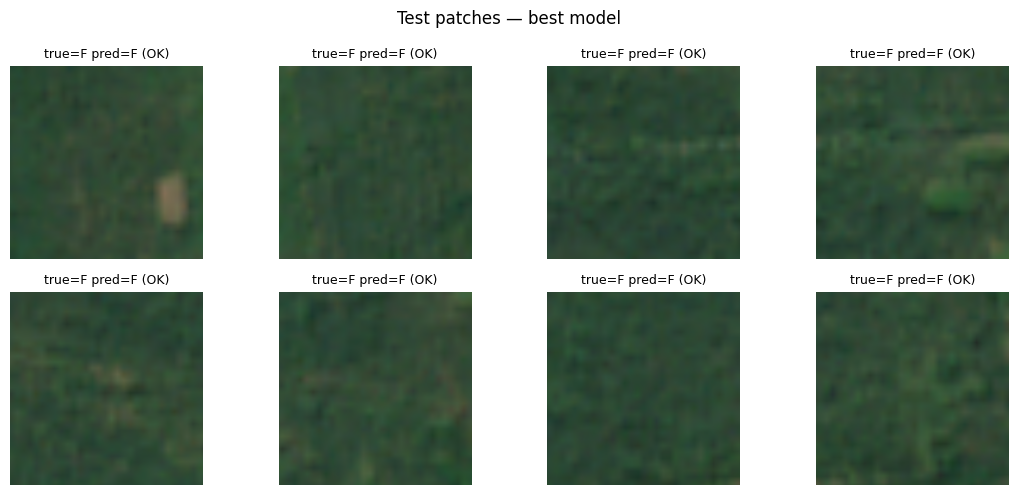

In [9]:
# Show a few test patches with true vs predicted tags
n_show = 8
fig, axes = plt.subplots(2, 4, figsize=(11, 5))
for ax, img, t, p in zip(axes.ravel(), X_test[:n_show], y_true[:n_show], y_pred[:n_show]):
    ax.imshow(img)
    ok = 'OK' if t == p else 'ERR'
    ax.set_title(f'true={"U" if t else "F"} pred={"U" if p else "F"} ({ok})', fontsize=9)
    ax.axis('off')
plt.suptitle('Test patches — best model')
plt.tight_layout()
plt.show()

### Discussion — findings and ANN vs Bayes (Lab 3)

**What the five runs show**
- With **Adam + ReLU**, the barebone, wider and deeper nets all reach strong train/test accuracy on this easy colour cue (forest darker/greener than urban).
- **Wider / deeper** add millions of parameters but do not improve over the barebone model here — capacity is already excessive for ~160 patches.
- **`tanh` and `SGD+momentum`** stayed near chance (0.5) with the same budget: optimiser and activation are not free knobs; Adam/ReLU were clearly more reliable for this Flattened RGB input.
- So the useful lesson is not “deeper is better”, but that **training setup matters**, and raw Dense ANNs are fragile relative to a simple spectral Bayes rule.

**Why Lab 3’s Bayesian classifier is often preferable here**
- Lab 3 fits a few Gaussians ($\boldsymbol{\mu},\Sigma$ per class) — **handful of parameters**, clear probabilistic meaning, fast on limited EO samples.
- Flattening $200\times200\times3$ into a Dense net creates **millions of weights**. With only ~160 training patches the model can memorise, training is heavier, and the decision rule is a black box.
- ANNs shine when the mapping $f$ is complex and data are abundant (or when we use CNNs that respect spatial structure). For a two-class spectral patch problem with scarce labelled AOIs, a **parametric Bayes / simple spectral rule** is usually the more honest and efficient tool — which is exactly the lab’s remark: *“you can see why, if possible, we prefer Bayesian classifiers.”*

### Summary

1. Patch tagging is a function $f:X\mapsto y$; an ANN approximates it.
2. Spatially split 200×200 patches give a clean train/test set without pixel leakage.
3. Barebone architecture: Flatten → small Dense → sigmoid.
4. Five permutations of width, depth, activation and optimiser were compared in one table and learning curves.
5. High ANN capacity is unnecessary for this Task-1 problem; Bayes from Lab 3 remains the lighter baseline.

AI tools were applied for formatting and plotting results.